# CA3

### Imports

In [220]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

### Reading data

In [221]:
# Setting random seed
seed = 42

# Reading data
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")


### Data exploration and visualisation

In [222]:
# Pairplot which saved locally. Will remove this code later?
# sns.pairplot(data=df_train,
#              hue='quality')

#### Summary

It is difficult to see a clear pattern between features and quality of wine. What I do see is that *alcohol* has a sort of grouping between good and bad wine. I can also see some grouping between good and bad for the *density* feature

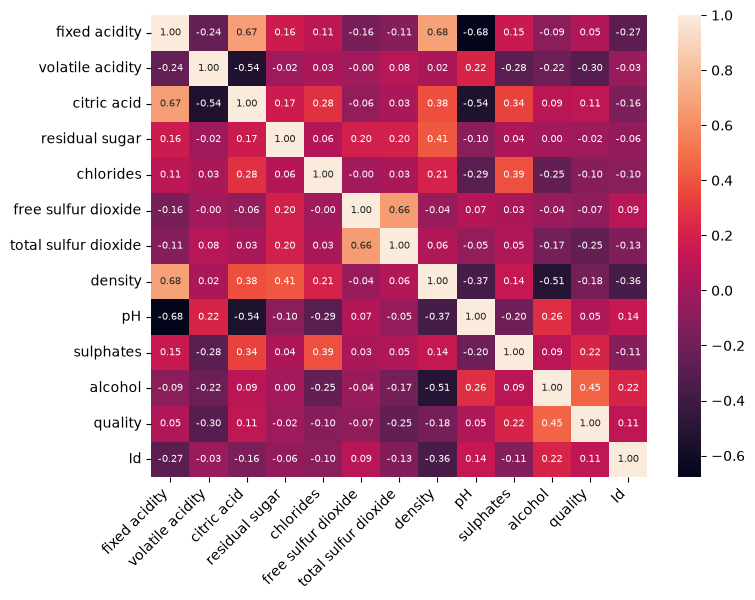

In [223]:
# Correlation between features
df_train_corr = df_train.corr()

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(data=df_train_corr,
            annot=True,
            annot_kws={"size":7},
            fmt=".2f"
            )
plt.xticks(rotation=45,
           ha='right')

# Save the figure
plt.savefig('feature_heatmap.png')

#### Summary

There are some features like *pH, density, citric acid* that have high correlation with many other features. I'd like to look into the importance of these features. Might be able to remove them?

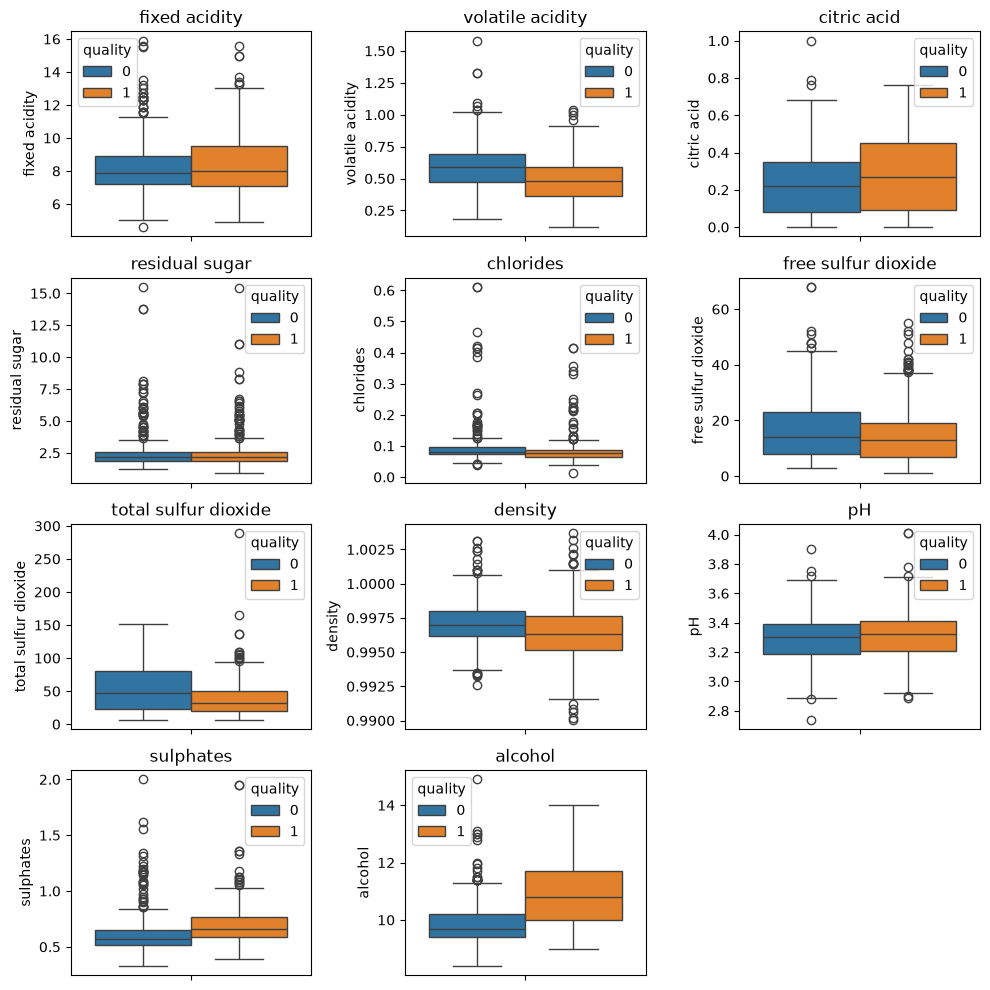

In [224]:
# Boxplots

# Features
features = df_train.select_dtypes(include=['number']).columns[:11]

fig, axes = plt.subplots(4, 3, figsize=(10, 10))
axes = axes.ravel()

# plotting for each feature
for i, feature in enumerate(features):
    sns.boxplot(data=df_train,
                y=feature,
                ax=axes[i],
                hue='quality')
    axes[i].set_title(feature)
    
# hiding last empty subplot
axes[11].axis('off')

plt.tight_layout()
plt.show()

#### Summary

There are some outliers that are very far out in *total sulfur dioxide, sulphates, residual sugar*. There is a single point in *citric acid* that is a potential outlier. 

*Chlorides* looks like a bit of a mess to me, so I don't want to touch that. 

*Volatile acidity* could also be something to look into. 

There are some features that don't have a lot of outliers. Could be removed because they are so few? For example *alcohol, free sulfur dioxide, volatile acidity*.

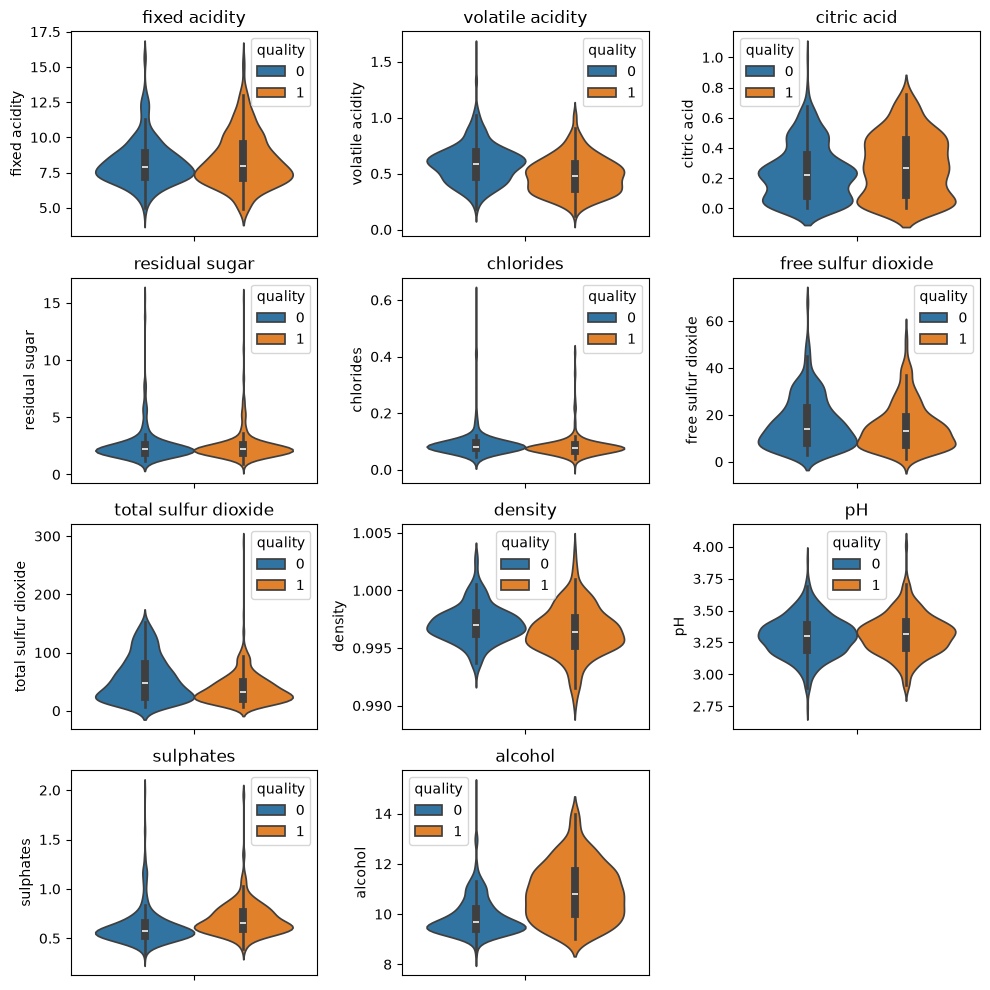

In [225]:
# Violin plot

# Features
features = df_train.select_dtypes(include=['number']).columns[:11]

fig, axes = plt.subplots(4, 3, figsize=(10, 10))
axes = axes.ravel()

# plotting for each feature
for i, feature in enumerate(features):
    sns.violinplot(data=df_train,
                   y=feature,
                   ax=axes[i],
                   hue='quality')
    axes[i].set_title(feature)
    
# hiding last empty subplot
axes[11].axis('off')

plt.tight_layout()
plt.show()

### Data cleaning

In [226]:
# Looking for missing values

df_train.isna().sum() # No missing values

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [227]:
# What more to clean?

### Data preprocessing and visualisation

I think I will remove features *fixed acidity, pH, citric acid*, and leave only *volatile acidity* as this seems to be to be a measure of almost the same thing. The correlation heatmap also supports that decision. I am also deciding to remove *free sulfur dioxide* because this has a high correlation with *total sulfur dioxide*, but *total sulfur dioxide* has a higher correlation with *quality* than the *free sulfur dioxide*. 

Might look into removing *density* as well. Will see. It is correlated with a lot of other features. I'll try to remove.

In [228]:
# Removing features I don't want to carry
X = df_train.drop(['fixed acidity', 'citric acid', 'sulphates', 'free sulfur dioxide', 'pH', 'density', 'Id', 'quality'], axis=1)
y = df_train['quality']

# Splitting into training and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)


### Modelling

In [229]:
classifier = RandomForestClassifier(n_estimators=100, random_state=seed)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
y_pred_train = classifier.predict(X_train)

Accuracy train score is: 100.00%
Accuracy test score is: 84.43%


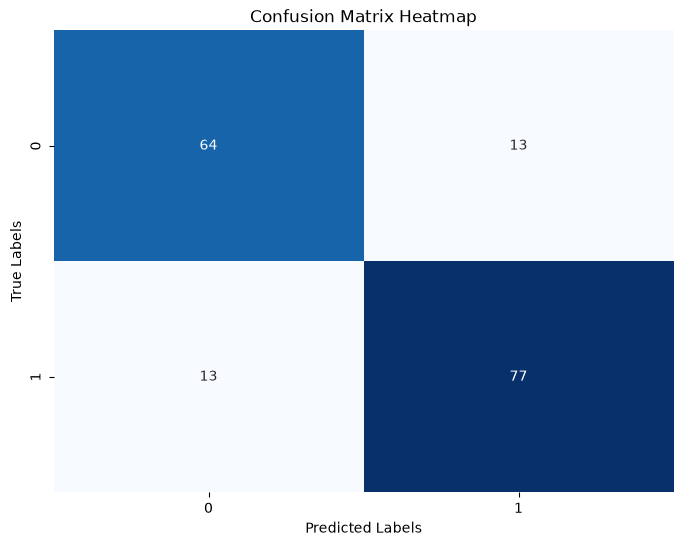

In [230]:
accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_test = accuracy_score(y_test, y_pred)

print(f'Accuracy train score is: {accuracy_train * 100:.2f}%')
print(f'Accuracy test score is: {accuracy_test * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False
            )

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

C:\Users\stige\AppData\Local\Temp\ipykernel_17104\3774977365.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')


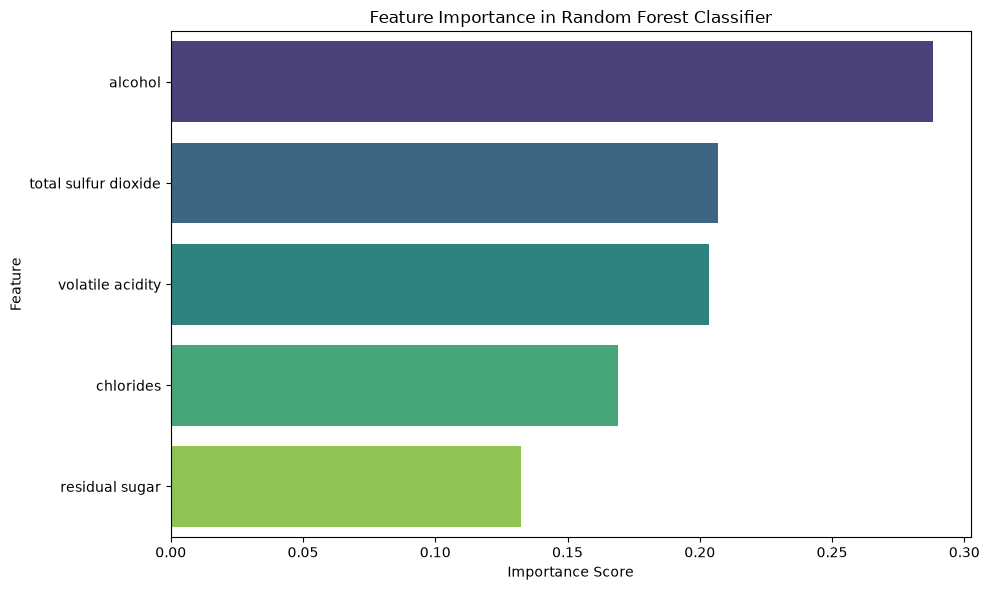

In [231]:
# Assuming 'rf' is your trained Random Forest Classifier
importances = classifier.feature_importances_
feature_names = X_train.columns

# Create a DataFrame and sort by importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
plt.title('Feature Importance in Random Forest Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Final evaluation

### Kaggle submission